In [5]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import scienceplots
from scipy.integrate import odeint
from multiprocessing import Pool
from tqdm import tqdm
from scipy.io import loadmat
import pandas as pd
from scipy import integrate
from scipy.optimize import fsolve
import operator
import pickle
import hdf5storage
from itertools import permutations
import itertools
import random
import powerlaw
import networkx as nx
import xgi

import sys;
# sys.path.append("/home/qinjiajie/jupyter_code/2-Tipping_point/High_order_dynamic")

# from utils import *
import utils
from importlib import reload
reload(utils)

<module 'utils' from '/home/qinjiajie/jupyter_code/2-Tipping_point/High_order_dynamic/utils.py'>

In [6]:
structure = hdf5storage.loadmat('sp_high_edges_3000.mat')

In [7]:
A = structure['A']
B = structure['B'][0]
lamda = np.linalg.eig(A)
index = np.argmax(lamda[0])
rho = np.real(lamda[0][index])
rho

30.138406722239793

In [8]:
result_large_origin = hdf5storage.loadmat('true_collapse_0703.mat')
true_collapse_tipping = result_large_origin['true_collapse']

In [9]:
result_large_2d = hdf5storage.loadmat('theory_collapse_0703.mat')
theory_collapse_tipping = result_large_2d['theory_collapse']

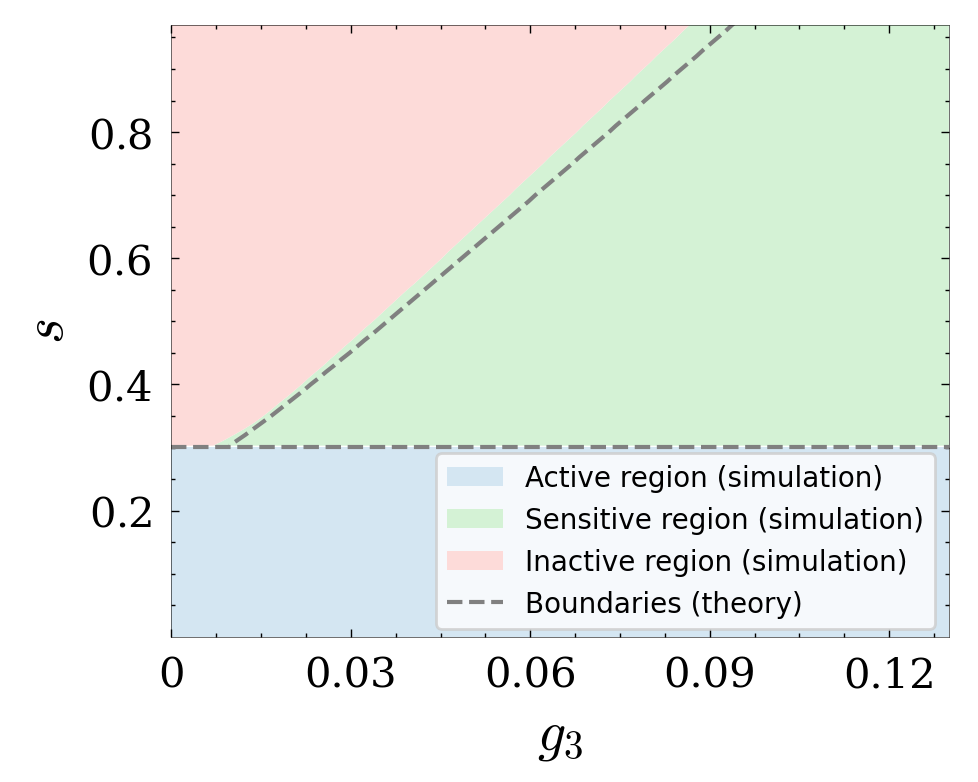

In [10]:
from matplotlib.ticker import MaxNLocator, FuncFormatter
with plt.style.context(['science', 'no-latex']): 
    fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(5, 4))
    bwith = 0.2  # 边框宽度设置为2
    ax.spines['bottom'].set_linewidth(bwith)
    ax.spines['left'].set_linewidth(bwith)
    ax.spines['top'].set_linewidth(bwith)
    ax.spines['right'].set_linewidth(bwith)

    ax.fill_between(np.arange(0,0.131,0.001),
                    0*np.ones(len(np.arange(0,0.131,0.001))),
                    0.01*rho*np.ones(len(np.arange(0,0.131,0.001))),
                    facecolor='#D4E6F2',label='Active region (simulation)')
    
    ax.fill_betweenx(-true_collapse_tipping[:,0],
                     true_collapse_tipping[:,1],
                    0.13*np.ones(len(true_collapse_tipping[:,0],)),
                    facecolor='#D4F2D5',label='Sensitive region (simulation)')

    ax.fill_betweenx(-true_collapse_tipping[:,0],
                     true_collapse_tipping[:,1],
                    0*np.ones(len(true_collapse_tipping[:,0],)),
                    facecolor='#FDDBD9',label='Inactive region (simulation)')
    ax.plot(theory_collapse_tipping[:,1],-theory_collapse_tipping[:,0],label='Boundaries (theory)',c='#808080',linewidth =1.5,linestyle='--')
    # # ax.plot([0.01025, 0.048775], [0.32, 1],label='Predicted collapsed boundary',c='#808080',linewidth =2.5,linestyle='--')
    ax.axhline(y=0.01*rho,c='#808080',linewidth =1.5,linestyle='--') # #d170a8
    # ax.plot(np.arange(0,0.05,0.0001), fs,label='Predicted collapsed boundary',c='#808080',linewidth =2.5,linestyle='--')
    
    # ax.plot(np.array([0,1])/83,[0,1])
    # ax.autoscale(tight=False)
    ax.set_ylim([0.0001,0.97])
    ax.set_xlim([0,0.13])
    # ax.scatter(0.045, 0.945, s=10,zorder=5)
    ax.set_xlabel(r'$g_3$',fontsize=20)
    ax.set_ylabel(r'$s$',fontsize=20)
    # ax.tick_params(width=0.1)
    ax.yaxis.set_major_locator(MaxNLocator(5))
    ax.xaxis.set_major_locator(MaxNLocator(5))
    # ax.set_title('Epidemic spreading',fontsize=20, pad=10)
    # ax.text(-0.2,1.1,'(a)',fontsize=15,transform=ax.transAxes)
    ax.legend(frameon=True,facecolor='white',fontsize=7, loc='upper left')
    ax.tick_params(axis='both', labelsize=13, pad=7)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: '0' if abs(x) < 1e-12 else f'{x:.2f}'))
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.legend(facecolor='white',fontsize=10, loc="lower right", bbox_to_anchor=(1, -0.01))
plt.rcParams['axes.linewidth'] = 0.1
plt.tight_layout()
plt.savefig("SIS_four_nodes.pdf", format='pdf', dpi=300)
plt.show()